# Land-Cover Segmentation with U-Net++ (DeepGlobe)

Semantic segmentation of satellite images into 7 land-cover classes (urban, agriculture, rangeland, forest, water, barren, unknown) with U-Net++ and an ImageNet-pretrained RegNetY-120 encoder.

In [ ]:
# @title 0. Installing Dependencies and Setting up mount Drive
# @markdown ### This Notebook Uses:
# @markdown - **PyTorch Lightning** – A high-level framework for PyTorch that simplifies training loops, checkpoints, early stopping.
# @markdown - **segmentation_models.pytorch (smp)**: U-Net++ with a pretrained encoder
# @markdown - **Qubvel Segmentation Models (segmentation_models.pytorch)** – A collection of popular neural networks for semantic segmentation based on PyTorch.
# @markdown - **Albumentations** – A fast and flexible image augmentation library. / image and mask augmentation
# @markdown - **Deepglobe Land Cover Dataset** – A fast and flexible image augmentation library.
# @markdown - **Gradio** – for GUI
# @markdown ---

# @markdown ### Dataset Requirements:
# @markdown To run this script properly, the **DeepGlobe Land Cover Classification Dataset** must be placed in your Google Drive.
# @markdown You can download it from [Kaggle](https://www.kaggle.com/datasets/balraj98/deepglobe-land-cover-classification-dataset). \
# @markdown Default dataset path: `drive/deepglobe`

!pip install -q git+https://github.com/PyTorchLightning/pytorch-lightning
!pip install -q git+https://github.com/qubvel/segmentation_models.pytorch
!pip install -q git+https://github.com/albumentations-team/albumentations
!pip install -q torchinfo
!pip install -q gradio

import os, torch, cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pytorch_lightning as pl
from glob import glob
from torch import nn
from tqdm.notebook import tqdm
from IPython.display import clear_output
from google.colab import drive
drive.mount('/content/drive')
torch.set_float32_matmul_precision('medium')

os.system('clear')
clear_output()
print("Setup complete. GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Setup complete. GPU: Tesla T4


In [ ]:
# @title 1. Settings, file list and train/val/test split
# @markdown | Setting | Value |
# @markdown | --- | --- |
# @markdown | Image size | 512  × 512 (higer values ran out of GPU memory) |
# @markdown | Batch size | 3 |
# @markdown | Max epochs | 40 (early stopping usually ends ~25) |
# @markdown | Split | 481 train / 121 val / 201 test (fixed seed for testing) |
from sklearn.model_selection import train_test_split

DATA_DIR   = "/content/drive/MyDrive/deepglobe"
IMAGE_SIZE = 512
BATCH_SIZE = 3
EPOCHS     = 40
SEED       = 42
NUM_WORKERS = min(4, os.cpu_count() or 2)

pl.seed_everything(SEED)

color_dict  = pd.read_csv(f"{DATA_DIR}/class_dict.csv")
CLASSES     = list(color_dict["name"])
NUM_CLASSES = len(CLASSES)

images = sorted(glob(f"{DATA_DIR}/train/*.jpg"))
masks  = sorted(glob(f"{DATA_DIR}/train/*.png"))
assert len(images) == len(masks) > 0, f"Found {len(images)} images and {len(masks)} masks"
for img, msk in zip(images, masks):
    assert os.path.basename(img).split("_")[0] == os.path.basename(msk).split("_")[0], (img, msk)

pd_dataset = pd.DataFrame({"IMAGES": images, "MASKS": masks})

# fixed random_state to make results comparable
pd_train, pd_test = train_test_split(pd_dataset, test_size=0.25, random_state=SEED)
pd_train, pd_val  = train_test_split(pd_train,   test_size=0.20, random_state=SEED)

print(f"Classes ({NUM_CLASSES}): {CLASSES}")
print(f"Train: {len(pd_train)} | Val: {len(pd_val)} | Test: {len(pd_test)} | Total: {len(pd_dataset)}")

INFO:lightning_fabric.utilities.seed:Seed set to 42


Classes (7): ['urban_land', 'agriculture_land', 'rangeland', 'forest_land', 'water', 'barren_land', 'unknown']
Train: 481 | Val: 121 | Test: 201 | Total: 803


In [ ]:
# @title 2. Mask conversion and augmentations
import albumentations as aug

def rgb2category(rgb_mask):
    """RGB mask (H, W, 3) -> class-index mask (H, W)."""
    category_mask = np.zeros(rgb_mask.shape[:2], dtype=np.uint8)
    for i, row in color_dict.iterrows():
        category_mask[np.all(rgb_mask == (row["r"], row["g"], row["b"]), axis=-1)] = i
    return category_mask

def category2rgb(category_mask):
    """Class-index mask (H, W) -> RGB mask (H, W, 3)."""
    rgb_mask = np.zeros(category_mask.shape[:2] + (3,), dtype=np.uint8)
    for i, row in color_dict.iterrows():
        rgb_mask[category_mask == i] = (row["r"], row["g"], row["b"])
    return rgb_mask

NORMALIZE = aug.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))  # ImageNet stats

# random changes only for training
train_augment = aug.Compose([
    aug.Resize(IMAGE_SIZE, IMAGE_SIZE),
    aug.HorizontalFlip(p=0.5),
    aug.VerticalFlip(p=0.5),
    aug.RandomBrightnessContrast(p=0.3),
    aug.Affine(scale=(0.8, 1.0), translate_percent=0.0, rotate=0.0, p=0.5),
    NORMALIZE,
])

# validation, test and the demo app: deterministic, so results are repeatable
eval_augment = aug.Compose([
    aug.Resize(IMAGE_SIZE, IMAGE_SIZE),
    NORMALIZE,
])

In [ ]:
# @title 3. Dataset and DataModule
from torch.utils.data import Dataset, DataLoader

class SegmentationDataset(Dataset):
    def __init__(self, df, augmentations):
        self.df = df.reset_index(drop=True)
        self.augmentations = augmentations

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        image = cv2.cvtColor(cv2.imread(row.IMAGES), cv2.COLOR_BGR2RGB)
        mask  = cv2.cvtColor(cv2.imread(row.MASKS),  cv2.COLOR_BGR2RGB)

        data  = self.augmentations(image=image, mask=mask)   # masks are resized with nearest-neighbour
        image, mask = data["image"], data["mask"]

        # image is already normalized by Albumentations: no extra division by 255
        image = torch.from_numpy(image.transpose(2, 0, 1)).float()
        mask  = torch.from_numpy(rgb2category(mask)).long().unsqueeze(0)
        return image, mask

class SegmentationDataModule(pl.LightningDataModule):
    def __init__(self, pd_train, pd_val, pd_test, batch_size):
        super().__init__()
        self.pd_train, self.pd_val, self.pd_test = pd_train, pd_val, pd_test
        self.batch_size = batch_size

    def setup(self, stage=None):
        self.train_dataset = SegmentationDataset(self.pd_train, train_augment)
        self.val_dataset   = SegmentationDataset(self.pd_val,   eval_augment)
        self.test_dataset  = SegmentationDataset(self.pd_test,  eval_augment)

    def _loader(self, dataset, shuffle):
        return DataLoader(dataset, batch_size=self.batch_size, shuffle=shuffle,
                          num_workers=NUM_WORKERS, persistent_workers=NUM_WORKERS > 0, pin_memory=True)

    def train_dataloader(self): return self._loader(self.train_dataset, True)
    def val_dataloader(self):   return self._loader(self.val_dataset,   False)
    def test_dataloader(self):  return self._loader(self.test_dataset,  False)

data_module = SegmentationDataModule(pd_train, pd_val, pd_test, batch_size=BATCH_SIZE)

In [ ]:
# @title 4. Model: U-Net++ with a pretrained RegNetY-120 encoder
# @markdown **Metrics**
# @markdown - **PixelAccuracy**: share of pixels with the correct class.
# @markdown - **IoU**: micro IoU per image, averaged over images (same metric as earlier runs).
# @markdown - **mIoU** (test only): IoU per class over the whole test set, averaged over the 6 real classes ("unknown" excluded).
from segmentation_models_pytorch import UnetPlusPlus
from segmentation_models_pytorch.losses import DiceLoss
from segmentation_models_pytorch.metrics import get_stats, iou_score, f1_score

UNKNOWN_IDX = CLASSES.index("unknown") if "unknown" in CLASSES else None

class SegmentationModel(pl.LightningModule):
    def __init__(self, lr=1e-4):
        super().__init__()
        self.save_hyperparameters()
        self.model = UnetPlusPlus(
            encoder_name="timm-regnety_120",
            encoder_weights="imagenet",
            in_channels=3,
            classes=NUM_CLASSES,
            activation=None,              # raw logits; the loss applies softmax itself
        )
        self.criterion = DiceLoss(mode="multiclass", from_logits=True)
        self._test_stats = []
        self.test_per_class = None

    def forward(self, x):
        return self.model(x)

    def _step(self, batch, stage):
        images, masks = batch
        logits = self(images)
        loss   = self.criterion(logits, masks)
        preds  = logits.argmax(dim=1, keepdim=True)
        tp, fp, fn, tn = get_stats(preds, masks, mode="multiclass", num_classes=NUM_CLASSES)

        # every pixel adds 1 to either TP or FN of its true class -> TP / (TP + FN) = pixel accuracy
        pixel_acc = tp.sum().float() / (tp.sum() + fn.sum()).float()
        self.log_dict({
            f"{stage}/Loss":          loss,
            f"{stage}/PixelAccuracy": pixel_acc,
            f"{stage}/IoU":           iou_score(tp, fp, fn, tn, reduction="micro-imagewise"),
            f"{stage}/F1":            f1_score(tp, fp, fn, tn, reduction="micro-imagewise"),
        }, prog_bar=True, on_step=False, on_epoch=True, batch_size=images.shape[0])
        return loss, tp, fp, fn

    def training_step(self, batch, batch_idx):
        return self._step(batch, "train")[0]

    def validation_step(self, batch, batch_idx):
        return self._step(batch, "val")[0]

    def on_test_epoch_start(self):
        self._test_stats = []

    def test_step(self, batch, batch_idx):
        loss, tp, fp, fn = self._step(batch, "test")
        self._test_stats.append((tp.sum(0).cpu(), fp.sum(0).cpu(), fn.sum(0).cpu()))
        return loss

    def on_test_epoch_end(self):
        tp, fp, fn = (torch.stack(s).sum(0).double() for s in zip(*self._test_stats))
        denom = tp + fp + fn
        iou = torch.where(denom > 0, tp / denom.clamp(min=1), torch.full_like(tp, float("nan")))
        keep = [i for i in range(NUM_CLASSES) if i != UNKNOWN_IDX and not torch.isnan(iou[i])]
        miou = iou[keep].mean()
        self.log("test/mIoU", miou)
        self.test_per_class = pd.DataFrame({
            "class": CLASSES,
            "IoU": iou.numpy().round(4),
            "pixels_in_test_set": (tp + fn).long().numpy(),
        })

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=self.hparams.lr)

model = SegmentationModel(lr=1e-4)

/usr/local/lib/python3.13/dist-packages/segmentation_models_pytorch/encoders/__init__.py:86: UserWarning: For 'tu-' (timm universal) encoders, `encoder_weights` should be set to True to download pretrained weights or None for random initialization. The pretrained variant is defined in the encoder name i.e 'tu-<model_name>.<pretrained_tag>'. Got encoder_weights='imagenet'.
  warnings.warn(


In [ ]:
# @title 5. Checkpoint, early stopping and trainer
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping
from pytorch_lightning.loggers import CSVLogger

# keep the epoch with the HIGHEST validation IoU
checkpoint_callback = ModelCheckpoint(
    dirpath="checkpoints",
    filename="best-{epoch:02d}",
    monitor="val/IoU",
    mode="max",
    save_top_k=1,
    verbose=True,
)

# stop when validation IoU has not improved for 5 epochs
early_stopping_callback = EarlyStopping(monitor="val/IoU", mode="max", patience=5)

logger = CSVLogger("lightning_logs", name="landcover-segmentation")

trainer = pl.Trainer(
    logger=logger,
    callbacks=[checkpoint_callback, early_stopping_callback],
    max_epochs=EPOCHS,
    accelerator="gpu",
    devices=1,
    precision="16-mixed",
    log_every_n_steps=10,
)

INFO:pytorch_lightning.utilities.rank_zero:Using 16bit Automatic Mixed Precision (AMP)
INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


In [ ]:
# @title 6. Train
trainer.fit(model, data_module)
print("Best checkpoint:", checkpoint_callback.best_model_path)
print("Best val/IoU:", float(checkpoint_callback.best_model_score))

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/callbacks/model_checkpoint.py:881: Checkpoint directory /content/checkpoints exists and is not empty.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/model_summary/model_summary.py:242: Precision 16-mixed is not supported by the model summary.  Estimated model size in MB will not be accurate. Using 32 bits instead.


┏━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name      ┃ Type         ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model     │ UnetPlusPlus │ 71.0 M │ train │     0 │
│ 1 │ criterion │ DiceLoss     │      0 │ train │     0 │
└───┴───────────┴──────────────┴────────┴───────┴───────┘

Trainable params: 71.0 M                                                                                           
Non-trainable params: 0                                                                                            
Total params: 71.0 M                                                                                               
Total estimated model params size (MB): 284.054                                                                    
Modules in train mode: 655                                                                                         
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

/usr/local/lib/python3.13/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

INFO:pytorch_lightning.utilities.rank_zero:Epoch 0, global step 161: 'val/IoU' reached 0.41468 (best 0.41468), saving model to '/content/checkpoints/best-epoch=00.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 1, global step 322: 'val/IoU' reached 0.52468 (best 0.52468), saving model to '/content/checkpoints/best-epoch=01.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 2, global step 483: 'val/IoU' reached 0.55877 (best 0.55877), saving model to '/content/checkpoints/best-epoch=02.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 3, global step 644: 'val/IoU' reached 0.68619 (best 0.68619), saving model to '/content/checkpoints/best-epoch=03.ckpt' as top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 4, global step 805: 'val/IoU' was not in top 1
INFO:pytorch_lightning.utilities.rank_zero:Epoch 5, global step 966: 'val/IoU' reached 0.69210 (best 0.69210), saving model to '/content/checkpoints/best-epoch=05.ckpt' as top 1
INFO:pytorch_l

Best checkpoint: /content/checkpoints/best-epoch=19.ckpt
Best val/IoU: 0.7424763441085815


INFO:pytorch_lightning.utilities.rank_zero:Restoring states from the checkpoint path at /content/checkpoints/best-epoch=19.ckpt
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:pytorch_lightning.utilities.rank_zero:Loaded model weights from the checkpoint at /content/checkpoints/best-epoch=19.ckpt


Output()

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃        Test metric        ┃       DataLoader 0        ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│          test/F1          │     0.838543176651001     │
│         test/IoU          │    0.7417793273925781     │
│         test/Loss         │    0.3317488729953766     │
│    test/PixelAccuracy     │     0.838543176651001     │
│         test/mIoU         │    0.6481495439380714     │
└───────────────────────────┴───────────────────────────┘

,class,IoU,pixels_in_test_set
0,urban_land,0.7492,6126647
1,agriculture_land,0.8359,30299713
2,rangeland,0.3579,4910039
3,forest_land,0.7365,5189647
4,water,0.7026,2097877
5,barren_land,0.5067,4066285
6,unknown,0.0000,736


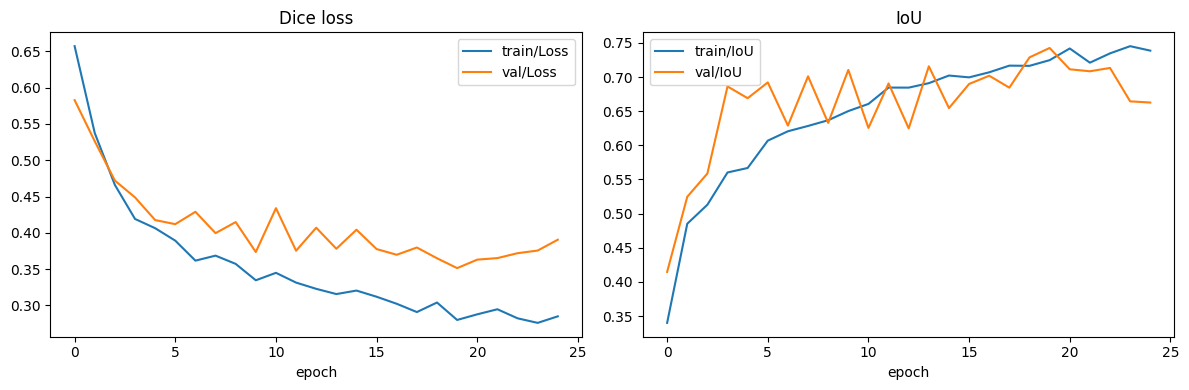

In [ ]:
# @title 7. Test the BEST checkpoint and plot training curves
results = trainer.test(model, data_module, ckpt_path="best")   # loads the best weights into `model`
display(model.test_per_class)

metrics = pd.read_csv(os.path.join(logger.log_dir, "metrics.csv"))
epoch_metrics = metrics.groupby("epoch").mean(numeric_only=True)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epoch_metrics[["train/Loss", "val/Loss"]].plot(ax=axes[0], title="Dice loss")
epoch_metrics[["train/IoU", "val/IoU"]].plot(ax=axes[1], title="IoU")
plt.tight_layout(); plt.savefig("training_curves.png", dpi=120); plt.show()

# keep a copy of the best weights in Drive
torch.save(model.state_dict(), f"{DATA_DIR}/unetpp_regnety120_landcover_best.pt")

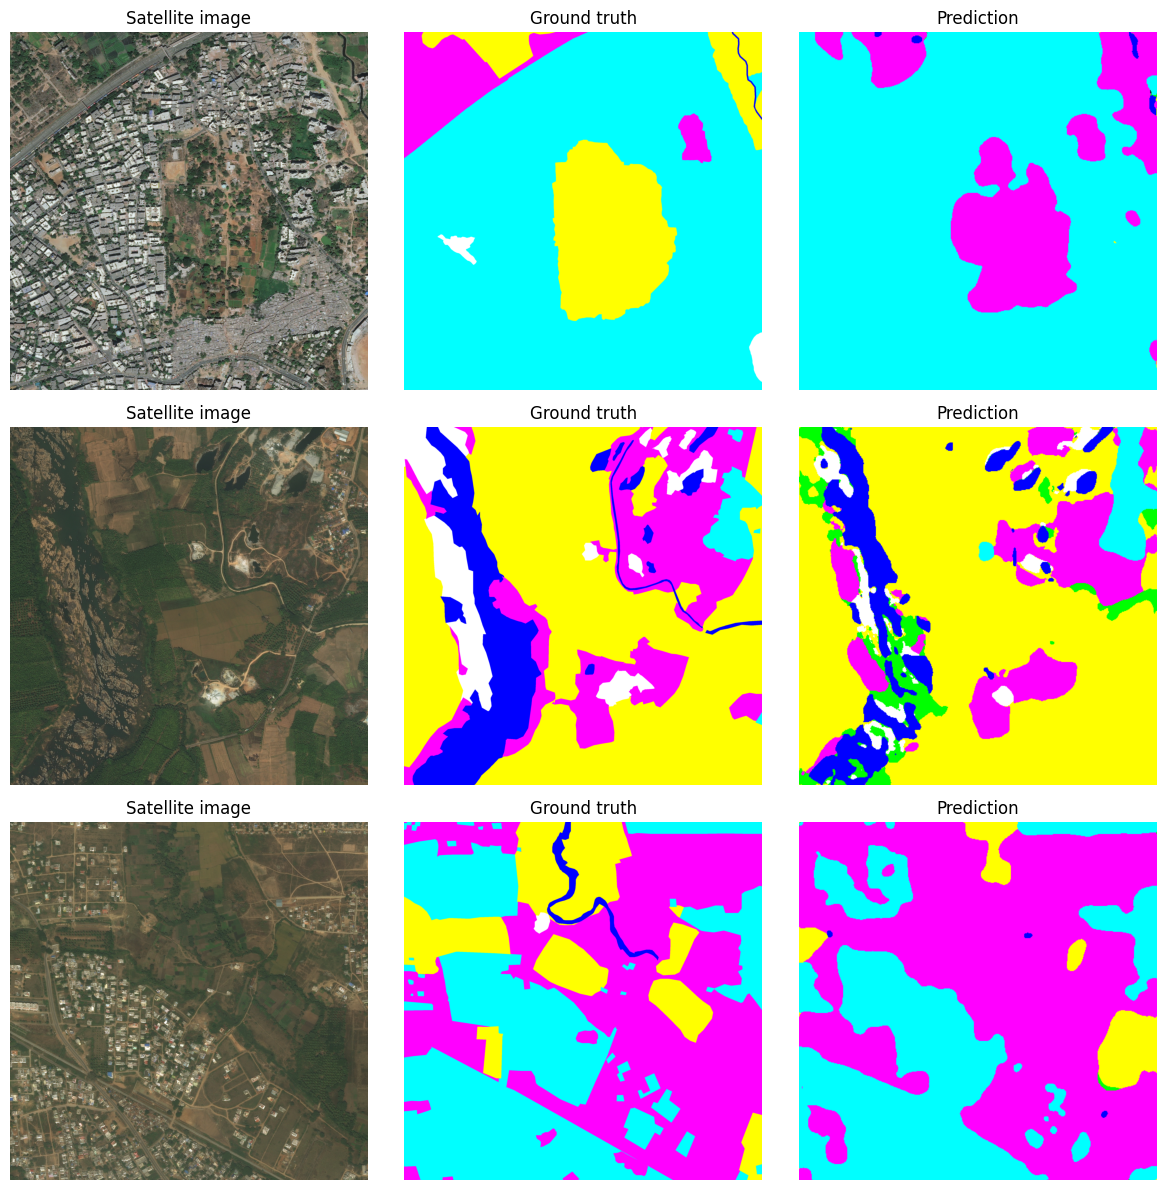

In [ ]:
# @title 8. Visualize predictions on test images (saved as predictions.png)
model.eval()
device = next(model.parameters()).device

def predict_mask(rgb_image):
    """RGB uint8 image (H, W, 3) -> class-index mask at the original size."""
    h, w = rgb_image.shape[:2]
    x = eval_augment(image=rgb_image)["image"]
    x = torch.from_numpy(x.transpose(2, 0, 1)).float().unsqueeze(0).to(device)
    with torch.no_grad():
        pred = model(x).argmax(dim=1)[0].cpu().numpy().astype(np.uint8)
    return cv2.resize(pred, (w, h), interpolation=cv2.INTER_NEAREST)

samples = pd_test.sample(3, random_state=SEED)
fig, axes = plt.subplots(len(samples), 3, figsize=(12, 4 * len(samples)))
for row_axes, (_, row) in zip(axes, samples.iterrows()):
    image = cv2.cvtColor(cv2.imread(row.IMAGES), cv2.COLOR_BGR2RGB)
    truth = cv2.cvtColor(cv2.imread(row.MASKS),  cv2.COLOR_BGR2RGB)
    pred  = category2rgb(predict_mask(image))
    for ax, img, title in zip(row_axes, (image, truth, pred), ("Satellite image", "Ground truth", "Prediction")):
        ax.imshow(img); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.savefig("predictions.png", dpi=120); plt.show()

In [ ]:
# @title 9. App Gradio UI
import gradio as gr
from PIL import Image, ImageDraw

def predict_land_cover(uploaded_img):
    image = np.array(uploaded_img.convert("RGB"))
    pred_mask = predict_mask(image)
    rgb_mask = category2rgb(pred_mask) # Convert prediction to RGB

    # Calculate class percentages
    unique, counts = np.unique(pred_mask, return_counts=True)
    percentages = {CLASSES[i]: round(c / pred_mask.size * 100, 2) for i, c in zip(unique, counts)}

    legend = Image.new("RGB", (300, max(30, 30 * len(percentages))), color="white")
    draw = ImageDraw.Draw(legend)
    for idx, (class_name, percent) in enumerate(percentages.items()):
        row = color_dict[color_dict["name"] == class_name].iloc[0]
        y = idx * 30
        draw.rectangle([0, y, 30, y + 30], fill=(int(row["r"]), int(row["g"]), int(row["b"])))
        draw.text((35, y + 8), f"{class_name}: {percent}%", fill="black")

    return Image.fromarray(rgb_mask), legend

#Launch Gradio
gr.Interface(
    fn=predict_land_cover,
    inputs=gr.Image(type="pil", label="Satellite image"),
    outputs=[gr.Image(type="pil", label="Segmentation mask"), gr.Image(type="pil", label="Class share")],
    title="Land-Cover Segmentation (U-Net++)",
    description="Upload a satellite image to get a land-cover mask and the share of each class.",
).launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://98c06d959d6a1d0abf.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
